# Task 5 (empty box): flight review and open questions

Milestone 2, Task 5: fly the drone with the payload box using our LQR controller and a mocap-only observer (the downward-facing sensors are removed). **Pass criterion:** at least one flight per box configuration that holds within 5 cm of the setpoint for 10 s.

**Where we are with the empty box:**
- **Passed:** hover run 2 and path run 3 (old firmware), and hover runs 3 and 4 (new firmware). Hover run 4, after replacing motor 1, is the cleanest: 2.1 cm max error over the best 10 s, 1% saturation, and 2 cm takeoff overshoot.
- **Failed:** path run 4, the first flight on the new firmware (corrected k_F and velocity feed-forward). Its hold failed with a 14.0 cm max error. Motor 1 saturated 61% of the time during the hold, and the yaw drifted steadily, reaching about 27° by the end of the hold.

**Questions for the TA** (details in section 6):
1. ~~Motor 1 saturating in path 4 and hover 3: prop, motor, or controller?~~ **Resolved:** it was the motor. With only motor 1 replaced and the firmware unchanged, hover 4 was clean, and motor 1 went from the highest command to the lowest. Remaining question: would you add a yaw integrator anyway, as protection against steady yaw torques?
2. Is scaling k_F *and* k_M by the measured hover thrust ratio reasonable, or should k_M be measured separately?
3. Hovering takes about 84% of full motor command with the empty box. What is a sensible way to handle the heavier partial and full configurations?
4. Is velocity feed-forward on v − v_des, with LQR gains designed for regulation, an acceptable way to track the path?

All numbers and plots below are computed from the logged flight files in this folder. Run All to reproduce them. Position error uses the mocap pose as received by the drone, so it differs by a few millimeters to about 2 cm from `milestone2_analysis.ipynb`, which uses the laptop's mocap log.

## 1. Setup

| | |
|---|---|
| Drone | Crazyflie 2.x (brushed), active marker deck, downward sensors removed |
| Mass | m = 0.0390 kg (drone + empty box v1) |
| Moments of inertia (pendulum method, `project-MOI/runs/box_v1`) | J_x = 1.85e-5 ± 0.45e-5, J_y = 1.90e-5 ± 0.64e-5, J_z = 3.14e-5 ± 0.63e-5 kg·m² |
| Controller | 17-state LQR (attitude, actuator delay τ_x, τ_y, integral action e_x, e_y, e_z), `controller_design.ipynb` |
| Observer | linear observer with mocap pose forwarded to the drone (`observer_design.ipynb`) |
| Path | 5 targets (seed 11), Held-Karp optimal order, 0.3 m/s at 0.5 m, drop-off at 0.2 m. A 15 s hold above the start right after takeoff is the 10 s / 5 cm check. |

**Firmware and gains for each flight:**

| flights | firmware | gains | what changed |
|---|---|---|---|
| hover runs 1–2, path run 1 | old (Lab 4 k_F) | `gains_box_empty_test.json` | m = 39 g, box J; `eq_f_z` = m g |
| path runs 2–3 | old | `gains_box_empty_ffz.json` | `eq_f_z` scaled by 0.859, the measured hover thrust (workaround with no reflash) |
| path run 4, hover runs 3–4 | **new** | `gains_box_empty.json` | k_F and k_M × 1.164 in the motor mixing; velocity feed-forward (v − v_des); `eq_f_z` = m g |

Where the 1.164 comes from: in hover run 2 the drone hovered at a mean commanded f_z of 0.3286 N (in Lab 4 k_F units), against m g = 0.3826 N, and 0.3826 / 0.3286 = 1.164.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from ae483.tools import load_hardware_data, resample_data_drone

# Same palette as milestone2_analysis.ipynb. Every series is also labeled or
# line-styled, so nothing depends on color alone.
C_BLUE, C_ORANGE, C_AQUA, C_YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
C_INK, C_MUTED, C_GRID = '#3d3d3a', '#8a8983', '#e4e3df'
XYZ = [C_BLUE, C_ORANGE, C_AQUA]
MOTORS = [C_BLUE, C_ORANGE, C_AQUA, C_YELLOW]
plt.rcParams.update({
    'axes.grid': True, 'grid.color': C_GRID, 'grid.linewidth': 0.8,
    'axes.edgecolor': C_MUTED, 'axes.labelcolor': C_INK, 'xtick.color': C_INK, 'ytick.color': C_INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.6, 'legend.frameon': False, 'font.size': 10,
})

M_MAX = 65535
TOL, WINDOW = 0.05, 10.0

RUNS = {
    'hover 1':  'task5_empty_run1.json',
    'hover 2':  'task5_empty_run2.json',
    'path 1':   'task5_path_empty_run1.json',
    'path 2':   'task5_path_empty_run2.json',
    'path 3':   'task5_path_empty_run3.json',
    'path 4':   'task5_path_empty_run4.json',
    'hover 3':  'task5_empty_run3.json',
    'hover 4':  'task5_empty_run4.json',
}

def load_run(filename):
    """Load one flight. Position error uses the mocap pose as received by the
    drone (ae483log.p_*_mocap), already in the takeoff frame, so no time
    alignment with the laptop's mocap log is needed."""
    with open(filename) as f:
        meta = json.load(f)
    d = resample_data_drone(load_hardware_data(filename)[0])
    log = lambda n: d[f'ae483log.{n}']
    r = {'meta': meta, 't': d['time']}
    r['p_des'] = np.column_stack([log('p_x_des'), log('p_y_des'), log('p_z_des')])
    r['p_est'] = np.column_stack([log('p_x'), log('p_y'), log('p_z')])
    r['p_mocap'] = np.column_stack([log('p_x_mocap'), log('p_y_mocap'), log('p_z_mocap')])
    r['motors'] = np.column_stack([log('m_1'), log('m_2'), log('m_3'), log('m_4')])
    r['psi'] = np.degrees(log('psi'))
    r['f_z'] = log('f_z')
    r['vbat'] = d['pm.vbat'] if 'pm.vbat' in d else None
    r['err'] = np.linalg.norm(r['p_mocap'] - r['p_des'], axis=1)

    # Flight: setpoint above the ground
    r['on'] = r['p_des'][:, 2] > 0.
    # Hold: the first continuous stretch at the hold setpoint (a path's return
    # leg passes the same point, so only the first stretch counts)
    task = meta['task5']
    if 'hold_point' in task:
        hold = np.all(np.isclose(r['p_des'], task['hold_point'], atol=1e-3), axis=1)
    else:
        hold = np.isclose(r['p_des'][:, 2], task['z_hover'], atol=1e-3)
    k0 = np.flatnonzero(hold)[0]
    k1 = k0 + np.argmin(hold[k0:]) if not hold[k0:].all() else len(hold)
    hold[:] = False
    hold[k0:k1] = True
    r['hold'] = hold
    r['path'] = r['on'] & (r['t'] > r['t'][k1 - 1]) & (r['p_des'][:, 2] > 0.15) if 'path' in meta else None
    return r

def best_window(r):
    """Smallest max error over any 10 s window inside the hold."""
    t, err, hold = r['t'], r['err'], r['hold']
    th = t[hold]
    best = (np.inf, None)
    for ts in th[th <= th[-1] - WINDOW]:
        w = hold & (t >= ts) & (t < ts + WINDOW)
        e = np.nanmax(err[w])
        if e < best[0]:
            best = (e, ts)
    return best

runs = {name: load_run(fn) for name, fn in RUNS.items()}
print('Loaded:', ', '.join(f'{k} ({v})' for k, v in RUNS.items()))

Loaded: hover 1 (task5_empty_run1.json), hover 2 (task5_empty_run2.json), path 1 (task5_path_empty_run1.json), path 2 (task5_path_empty_run2.json), path 3 (task5_path_empty_run3.json), path 4 (task5_path_empty_run4.json), hover 3 (task5_empty_run3.json), hover 4 (task5_empty_run4.json)


## 2. Summary of every empty-box flight

**Column definitions:**
- **best 10 s max err:** the pass criterion. It's the smallest, over every 10 s window of the hold, of the maximum 3D distance between the mocap position and the setpoint.
- **path RMS:** error along the delivery path, after the hold.
- **saturated:** the share of flight time with any motor at 65535.
- **hover cmd:** the mean motor command during the hold.

In [2]:
rows = []
for name, r in runs.items():
    e_best, _ = best_window(r)
    on = r['on']
    sat = (r['motors'][on] >= M_MAX).any(axis=1).mean()
    hover_cmd = r['motors'][r['hold'] & (r['motors'].sum(axis=1) > 0)].mean()   # only while the motors run
    path_rms = np.sqrt(np.nanmean(r['err'][r['path']] ** 2)) if r['path'] is not None and r['path'].any() else np.nan
    vbat = f"{r['vbat'][~on][:200].mean():.2f}" if r['vbat'] is not None else '-'
    rows.append((name, r['meta']['gains_filename'], 100 * e_best, 'PASS' if e_best < TOL else 'FAIL',
                 100 * path_rms, 100 * sat, hover_cmd / M_MAX * 100, vbat))

hdr = f"{'flight':<9}{'gains':<28}{'best 10 s max err':>18}{'':>6}{'path RMS':>10}{'saturated':>11}{'hover cmd':>11}{'V at rest':>11}"
print(hdr)
print('-' * len(hdr))
for n, g, e, p, pr, s, h, v in rows:
    pr_s = f'{pr:.1f} cm' if np.isfinite(pr) else '-'
    print(f'{n:<9}{g:<28}{e:>15.1f} cm{p:>6}{pr_s:>10}{s:>10.0f}%{h:>10.0f}%{v:>11}')

flight   gains                        best 10 s max err        path RMS  saturated  hover cmd  V at rest
--------------------------------------------------------------------------------------------------------
hover 1  gains_box_empty_test.json               7.0 cm  FAIL         -        16%        84%          -
hover 2  gains_box_empty_test.json               2.9 cm  PASS         -         1%        84%          -
path 1   gains_box_empty_test.json              52.9 cm  FAIL   56.7 cm        69%        86%          -
path 2   gains_box_empty_ffz.json               36.3 cm  FAIL         -        37%        84%       3.77
path 3   gains_box_empty_ffz.json                3.3 cm  PASS   23.3 cm        21%        85%       4.08
path 4   gains_box_empty.json                   14.0 cm  FAIL   15.0 cm        39%        86%       4.06
hover 3  gains_box_empty.json                    2.8 cm  PASS         -        14%        86%          -
hover 4  gains_box_empty.json                    2.1 cm

**Notes on each flight:**
- **Hover 1–2:** these flights were before the hover-thrust correction. They overshoot on takeoff (hover 2 reaches 0.42 m against a 0.3 m setpoint) while the z integrator winds up to cancel a feed-forward that is 14% too high. Hover 1 (Nov 9, earlier gains) held to 7.0 cm. Hover 2 passed.
- **Path 1:** crashed during the hold, before the path started. The z oscillation grew while the motors were pinned at 65535. The battery was not logged on this flight. The most likely cause is a low battery on top of the 14% feed-forward excess.
- **Path 2:** the battery was low (3.77 V at rest, 2.86 V minimum in flight). Disregard this run.
- **Path 3:** the hold passed. Path tracking lagged the moving setpoint by 25–35 cm (section 4).
- **Path 4:** on the new firmware, path tracking improved (section 4), but the hold failed because of motor 1 saturation (section 5).
- **Hover 3 (new firmware):** passed (2.8 cm, 13–23 s). Two oddities:
  - **Motor 1 runs high again.** It averaged about 61,000 during the hold. Then, at about 23 s, it was pinned at 65535 for most of 3 s, and the drone dropped from 0.30 m to 0.06 m before overshooting to 0.50 m.
  - **Late motor start.** The motors started 5 s after the takeoff setpoint began, so the drone jumped straight to the 0.3 m setpoint and overshot to 0.41 m. No other flight shows this delay.
- **Hover 4 (new firmware, motor 1 replaced):** passed (2.1 cm). Motor 1 dropped from about 61,000 to about 49,000 (now the lowest), with 1% saturation and yaw within 4°. The motor 1 problem in path 4 and hover 3 was a weak motor, not the firmware. The late motor start in hover 3 did not repeat.

## 3. Each flight
For every flight, the plots show position against setpoint, the 3D error with the 5 cm limit, the four motor commands with the 65535 limit, and yaw. The shaded band marks the hold.

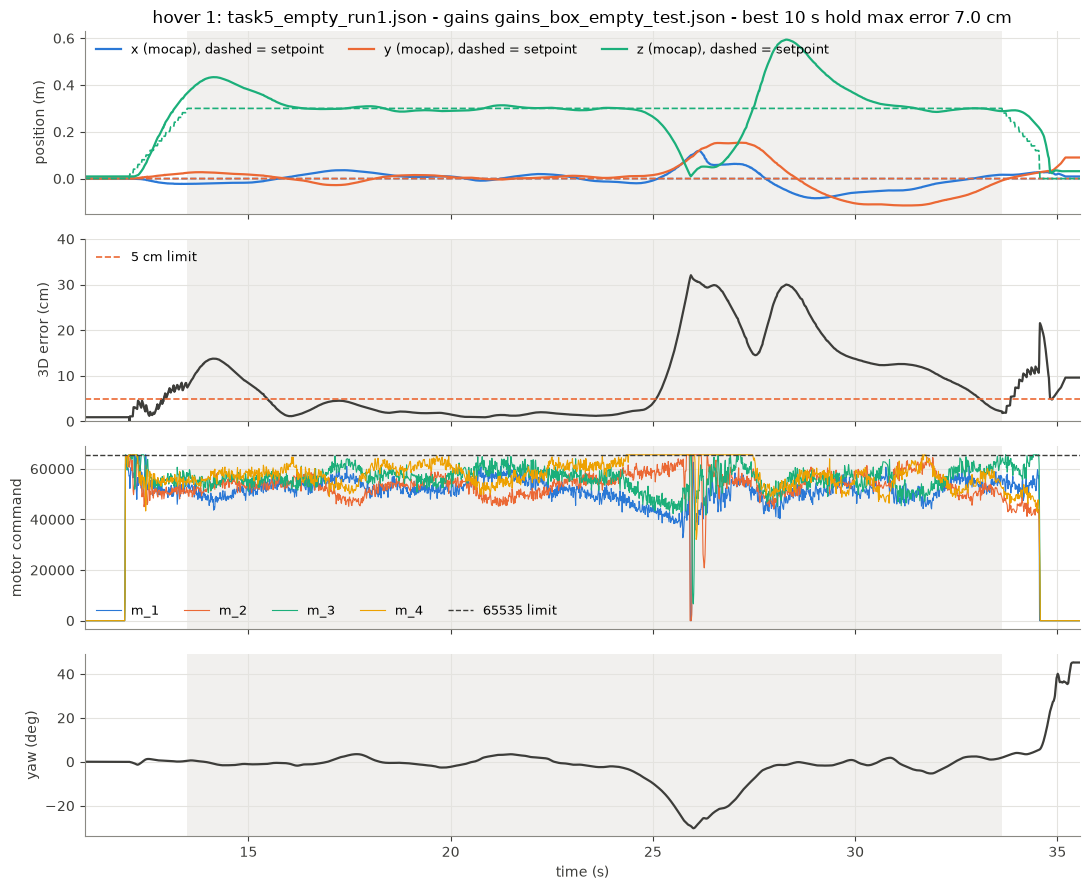

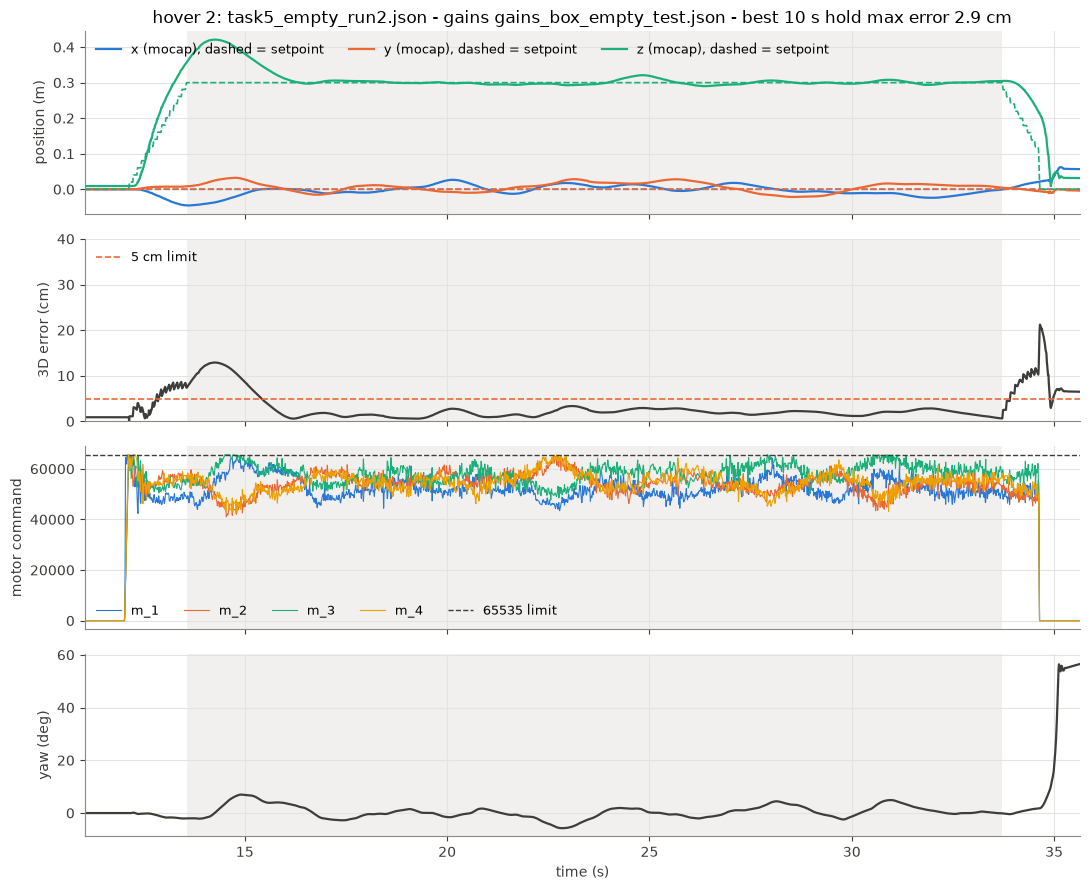

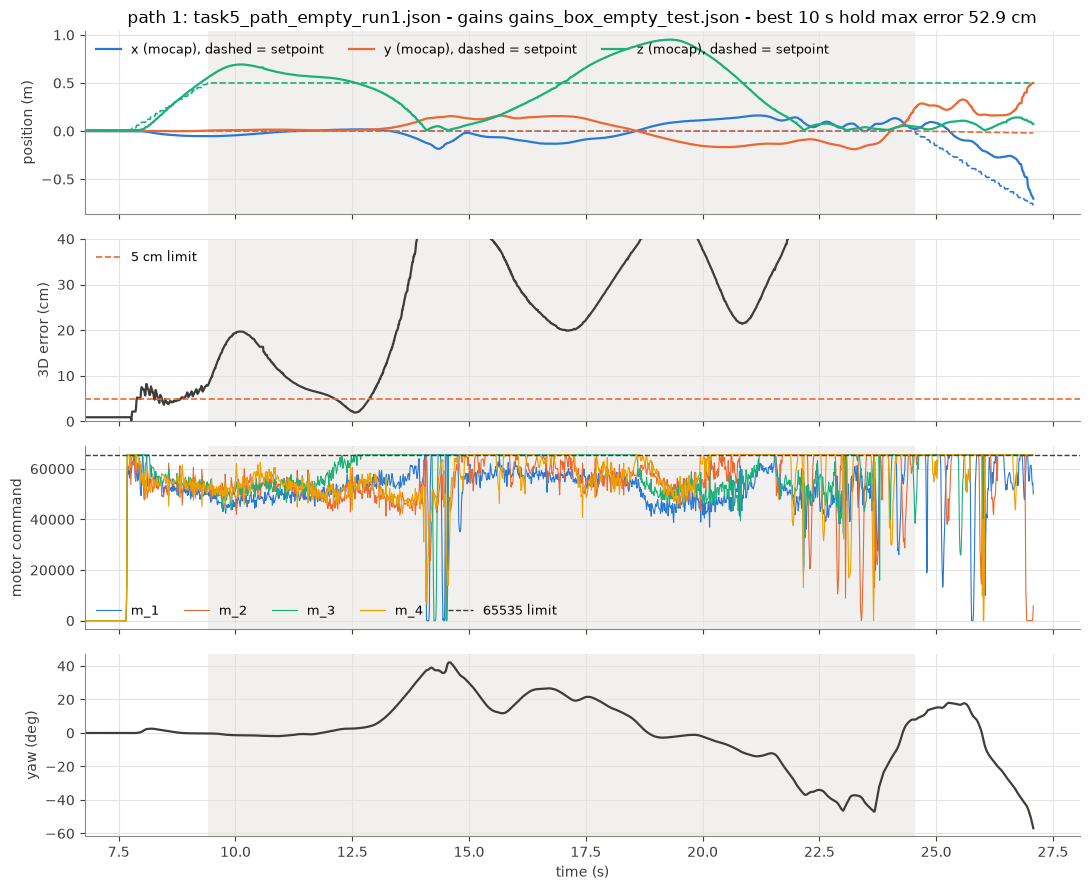

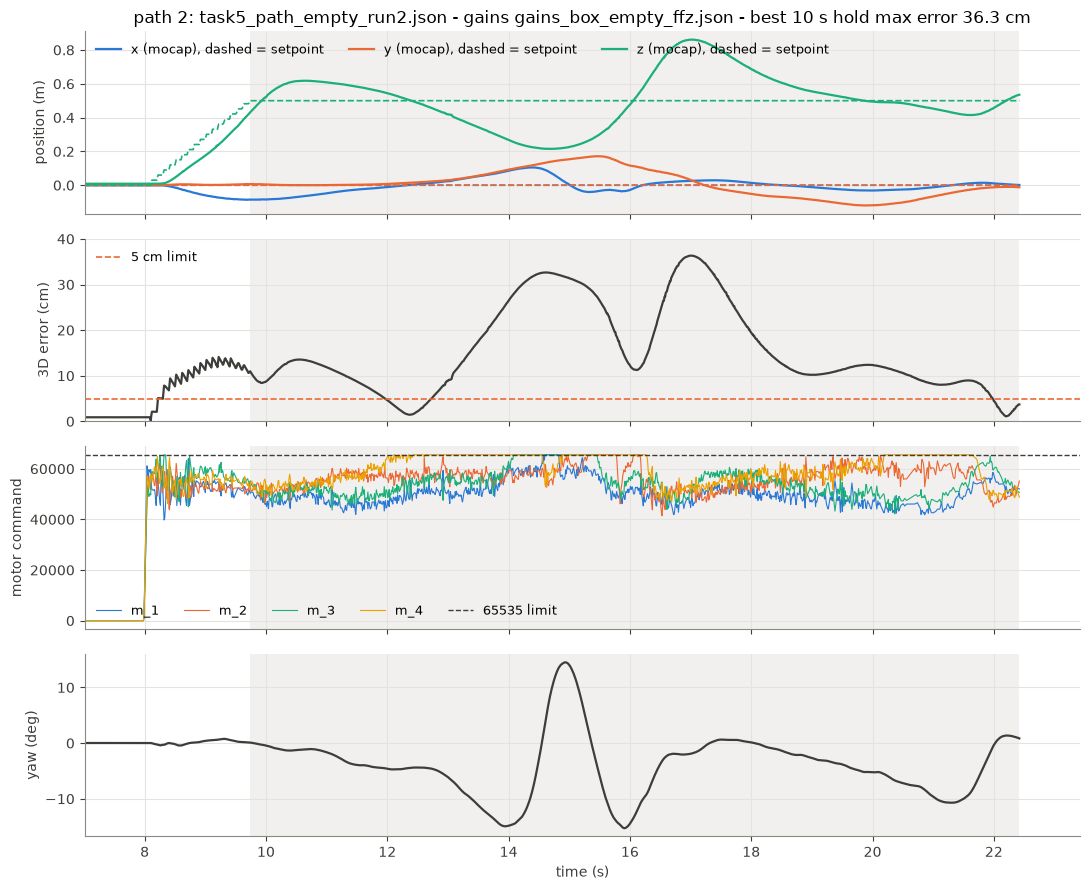

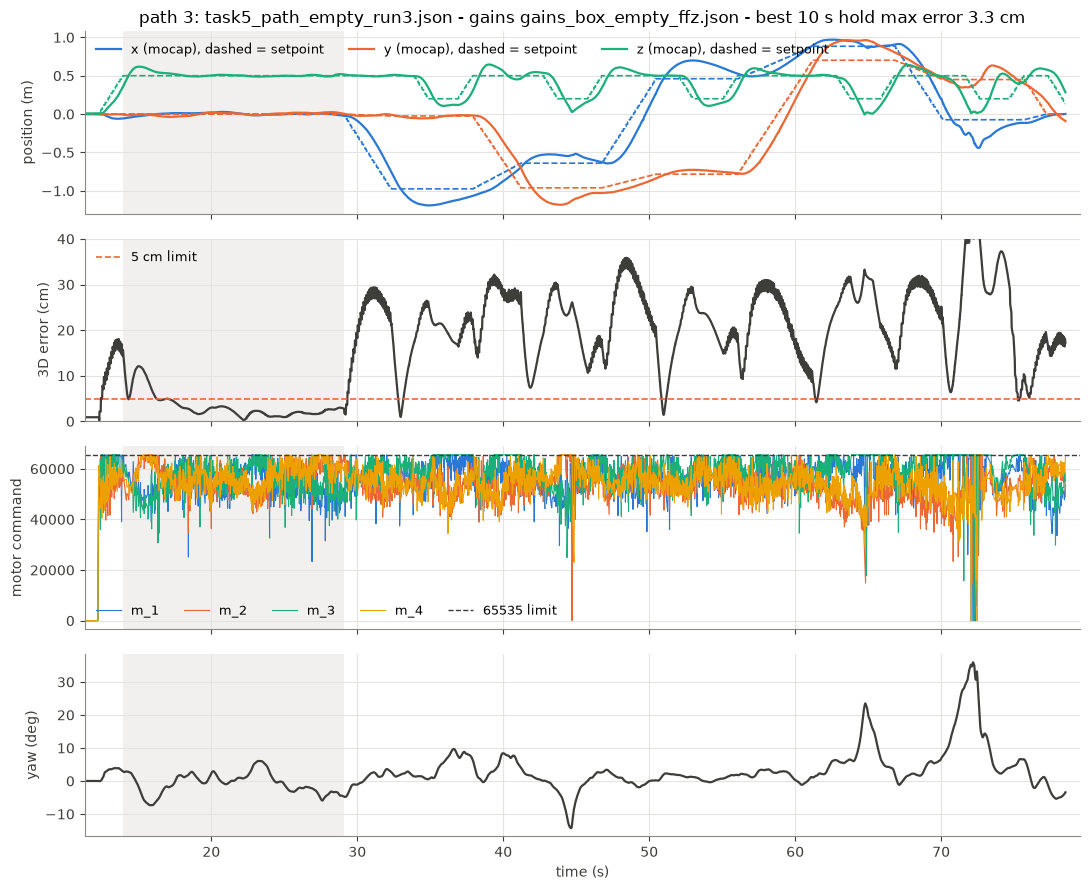

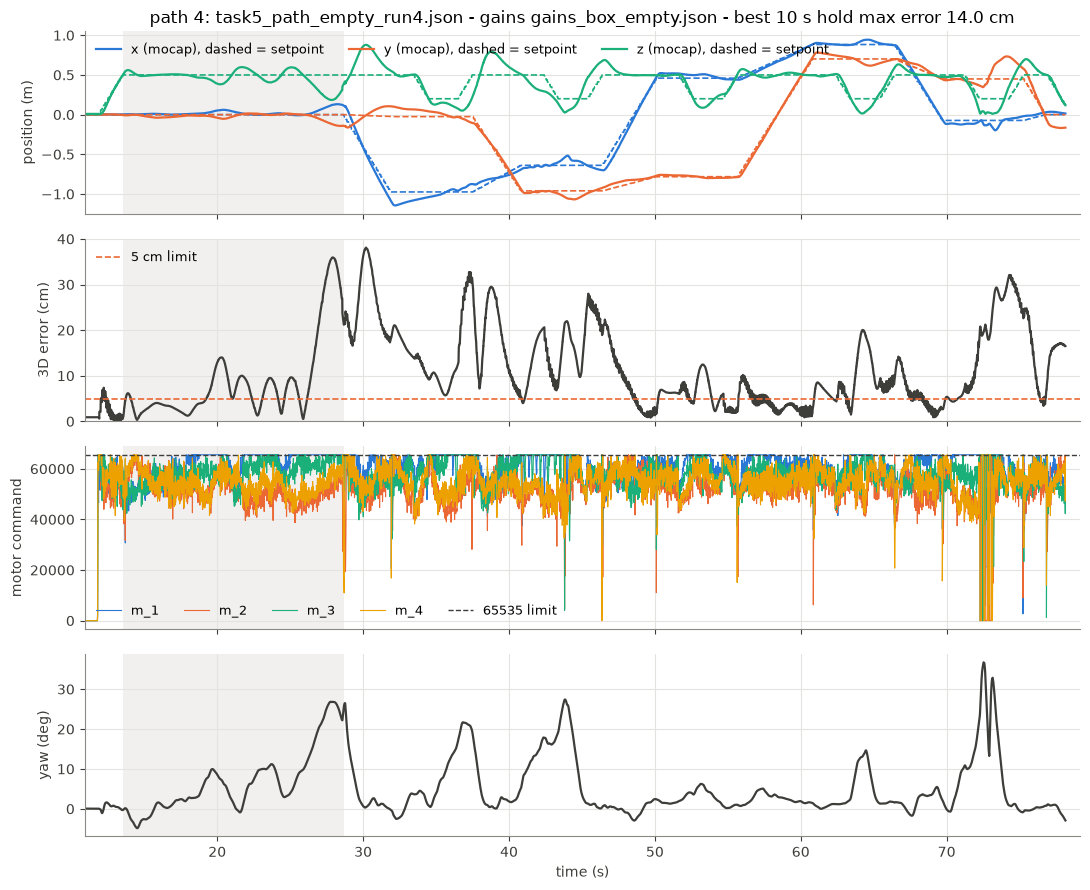

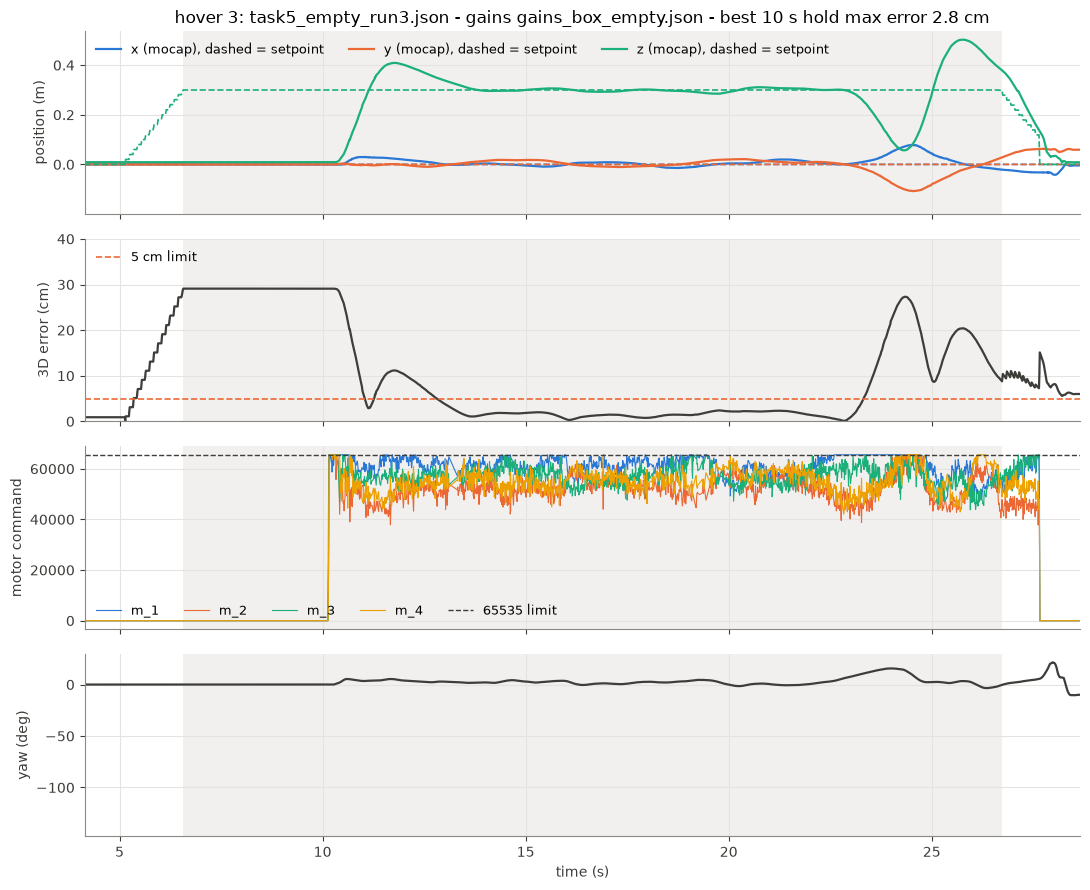

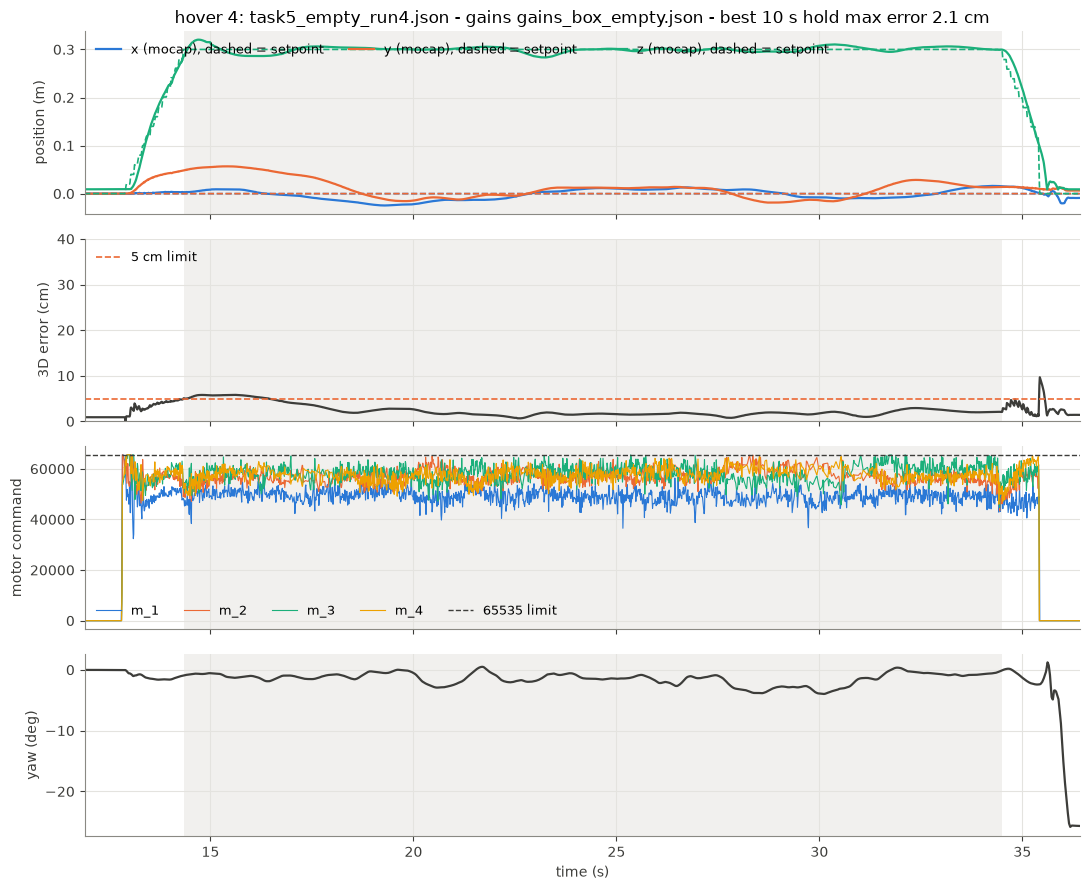

In [3]:
def plot_run(name, r):
    t, on = r['t'], r['on']
    t0, t1 = t[on][0] - 1, t[on][-1] + 1
    th = r['t'][r['hold']]
    fig, ax = plt.subplots(4, 1, figsize=(11, 9), sharex=True, tight_layout=True)
    for k, c in enumerate('xyz'):
        ax[0].plot(t, r['p_des'][:, k], '--', color=XYZ[k], lw=1.2)
        ax[0].plot(t, r['p_mocap'][:, k], color=XYZ[k], label=f'{c} (mocap), dashed = setpoint')
    ax[0].set_ylabel('position (m)')
    ax[0].legend(ncol=3, loc='upper left', fontsize=9)
    ax[1].plot(t, 100 * r['err'], color=C_INK)
    ax[1].axhline(100 * TOL, color=C_ORANGE, ls='--', lw=1.2, label='5 cm limit')
    ax[1].set_ylim(0, 40)
    ax[1].set_ylabel('3D error (cm)')
    ax[1].legend(loc='upper left', fontsize=9)
    for j in range(4):
        ax[2].plot(t, r['motors'][:, j], color=MOTORS[j], lw=0.8, label=f'm_{j + 1}')
    ax[2].axhline(M_MAX, color=C_INK, ls='--', lw=1, label='65535 limit')
    ax[2].set_ylabel('motor command')
    ax[2].legend(ncol=5, loc='lower left', fontsize=9)
    ax[3].plot(t, r['psi'], color=C_INK)
    ax[3].set_ylabel('yaw (deg)')
    ax[3].set_xlabel('time (s)')
    for a in ax:
        a.axvspan(th[0], th[-1], color=C_GRID, alpha=0.5, lw=0)
    ax[3].set_xlim(t0, t1)
    e_best, _ = best_window(r)
    ax[0].set_title(f"{name}: {RUNS[name]} - gains {r['meta']['gains_filename']} - best 10 s hold max error {100 * e_best:.1f} cm")
    plt.show()

for name, r in runs.items():
    plot_run(name, r)

## 4. Path tracking: lag in path 3, feed-forward in path 4

Path 3 used plain position setpoints. `move_smooth` moves the desired position at 0.3 m/s, but the desired velocity sent to the drone is 0. The velocity term in the controller therefore pulls toward zero velocity, and the drone settles behind the setpoint by roughly

  lag ≈ speed × k_v / k_p = 0.3 m/s × (0.0250 / 0.0208) s ≈ 0.36 m (path 3 gains, x and y loops).

The x and y integrators then wind up during each leg and overshoot each target by about 20 cm.

For path 4, the client sends full-state setpoints that include the desired velocity, and the firmware uses (v − v_des) in place of v. Plain position setpoints have v_des = 0, so hover flights are unchanged.

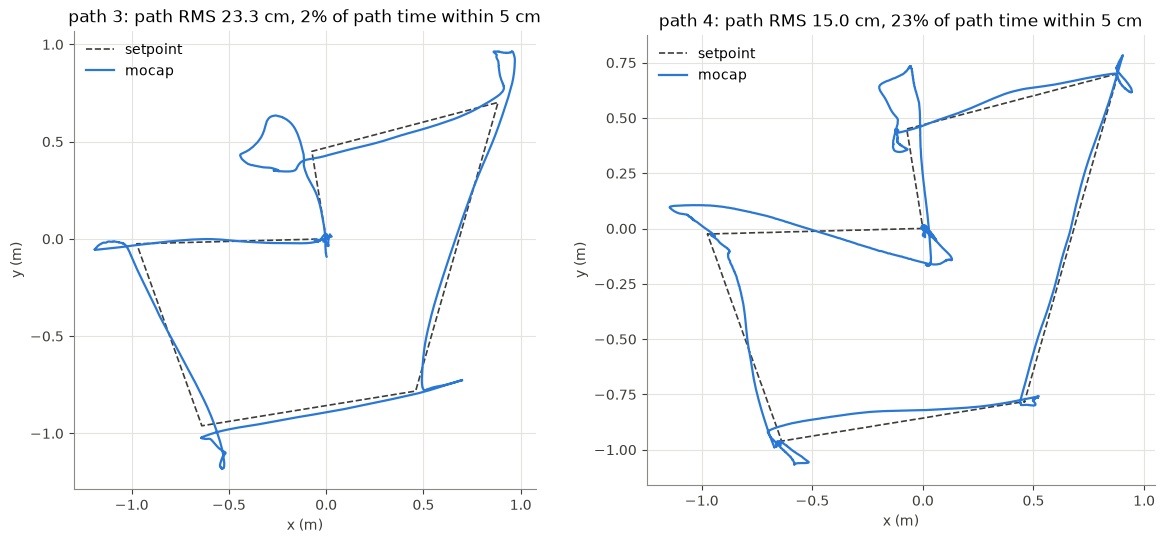

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.5), tight_layout=True)
for a, name in zip(axs, ['path 3', 'path 4']):
    r = runs[name]
    on = r['on']
    a.plot(r['p_des'][on, 0], r['p_des'][on, 1], '--', color=C_INK, lw=1.2, label='setpoint')
    a.plot(r['p_mocap'][on, 0], r['p_mocap'][on, 1], color=C_BLUE, label='mocap')
    e = r['err'][r['path']]
    a.set_title(f'{name}: path RMS {100 * np.sqrt(np.nanmean(e ** 2)):.1f} cm, '
                f'{100 * np.nanmean(e < TOL):.0f}% of path time within 5 cm')
    a.set_xlabel('x (m)')
    a.set_ylabel('y (m)')
    a.set_aspect('equal')
    a.legend(loc='upper left')
plt.show()

## 5. Hold failure in path 4: one motor saturating

The table compares the two path flights over the same part of the hold, from 2 s after the hold starts to its end. Path 3 used the old firmware and path 4 the new one; the battery was about the same.

In [5]:
def hold_stats(r):
    t = r['t']
    th = t[r['hold']]
    w = r['hold'] & (t > th[0] + 2.)
    m = r['motors'][w]
    return {
        'height std (cm)': 100 * r['p_mocap'][w, 2].std(),
        'any motor saturated (%)': 100 * (m >= M_MAX).any(axis=1).mean(),
        **{f'm_{j + 1} saturated (%)': 100 * (m[:, j] >= M_MAX).mean() for j in range(4)},
        **{f'm_{j + 1} mean': m[:, j].mean() for j in range(4)},
        '(m_1 + m_3) - (m_2 + m_4)': (m[:, 0] + m[:, 2] - m[:, 1] - m[:, 3]).mean(),
        'yaw mean (deg)': r['psi'][w].mean(),
        'yaw std (deg)': r['psi'][w].std(),
        'battery (V)': r['vbat'][w].mean() if r['vbat'] is not None else np.nan,
    }

s3, s4 = hold_stats(runs['path 3']), hold_stats(runs['path 4'])
print(f"{'during the hold':<28}{'path 3':>12}{'path 4':>12}")
print('-' * 52)
for k in s3:
    print(f'{k:<28}{s3[k]:>12.1f}{s4[k]:>12.1f}')

during the hold                   path 3      path 4
----------------------------------------------------
height std (cm)                      1.5        10.5
any motor saturated (%)              3.3        60.8
m_1 saturated (%)                    0.3        60.8
m_2 saturated (%)                    0.2         0.3
m_3 saturated (%)                    0.9         4.4
m_4 saturated (%)                    2.0         0.0
m_1 mean                         54289.3     62933.5
m_2 mean                         56059.4     51018.4
m_3 mean                         56370.2     59490.1
m_4 mean                         57116.8     53304.7
(m_1 + m_3) - (m_2 + m_4)        -2516.7     18100.5
yaw mean (deg)                      -0.6         8.2
yaw std (deg)                        3.0         7.6
battery (V)                          3.5         3.5


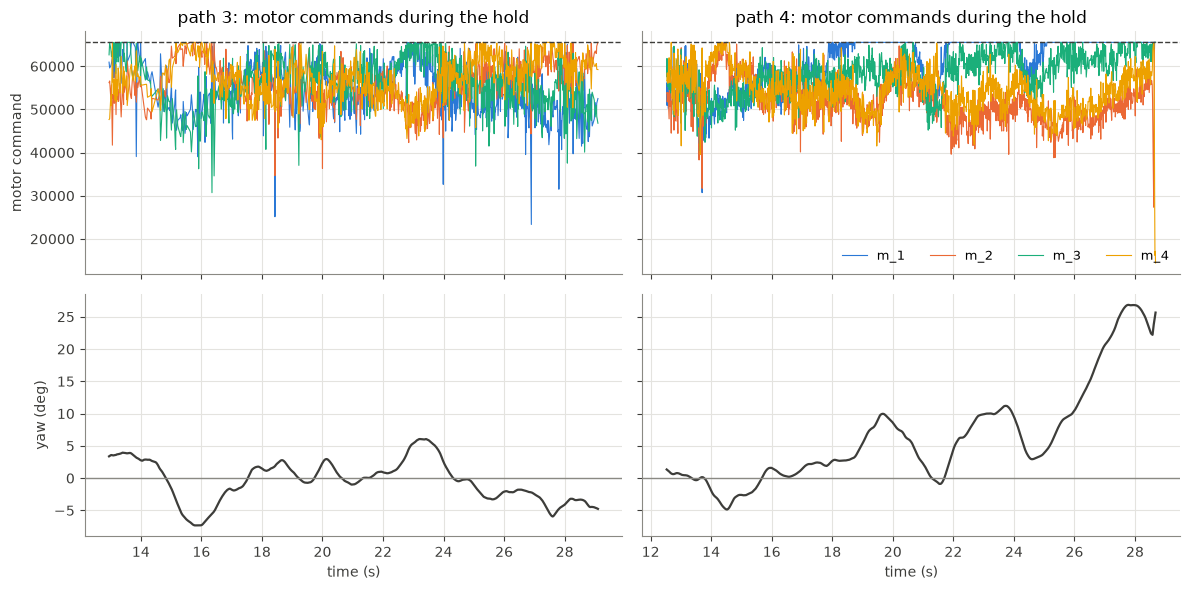

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(12, 6), sharex='col', sharey='row', tight_layout=True)
for col, name in enumerate(['path 3', 'path 4']):
    r = runs[name]
    t = r['t']
    th = t[r['hold']]
    w = (t >= th[0] - 1) & (t <= th[-1])
    for j in range(4):
        axs[0, col].plot(t[w], r['motors'][w, j], color=MOTORS[j], lw=0.8, label=f'm_{j + 1}')
    axs[0, col].axhline(M_MAX, color=C_INK, ls='--', lw=1)
    axs[0, col].set_title(f'{name}: motor commands during the hold')
    axs[1, col].plot(t[w], r['psi'][w], color=C_INK)
    axs[1, col].axhline(0, color=C_MUTED, lw=1)
    axs[1, col].set_xlabel('time (s)')
axs[0, 0].set_ylabel('motor command')
axs[1, 0].set_ylabel('yaw (deg)')
axs[0, 1].legend(ncol=4, loc='lower right', fontsize=9)
plt.show()

**What we think is happening:**
- **A yaw torque the controller is fighting.** In the mixing, m_1 and m_3 share the same yaw-torque sign. During the path 4 hold, that pair averages about 18,000 counts more than m_2 + m_4 (−2,500 in path 3). Even so, the yaw drifts up through the hold, reaching about 27° (mean 8°, std 7.6°), against a mean of −0.6° in path 3. Once m_1 is clipped at 65535, the commanded yaw correction is no longer delivered, so the yaw keeps drifting. Yaw also has no integrator to absorb a steady disturbance.
- **The firmware change can't explain it.** For the same physical yaw torque, the new mixing and gains should give a slightly smaller yaw offset (k_tau_z_psi × mixing coefficient rises from about 67k to about 73k counts per radian). So the larger offset points to a physical change between the two flights: a prop, a motor, or how the box sits.
- **The saturation causes the height bounce.** With hover already at about 84% of full command, the extra yaw demand pins m_1 at 65535. Whenever a motor is clipped, the commanded thrust and torques are not delivered, the height loop loses authority, and the height varies with a standard deviation of 10.5 cm (1.5 cm in path 3). That is what fails the 5 cm hold.

**Outcome:** replacing motor 1 fixed it. Hover 4 (section 2) had the same firmware and gains, and motor 1 ran at about 49,000, with 1% saturation.

## 6. Questions for the TA

1. **Yaw imbalance (section 5), resolved: a weak motor 1.** Replacing it fixed the saturation (hover 4). Would you still add a yaw integrator (an e_ψ state) to absorb steady yaw torques, or is fixing the hardware enough?
2. **k_M scaling.** We measured only the hover thrust, which gives the k_F correction (× 1.164). We scaled k_M by the same factor, assuming the same motors and props. Is that reasonable, or should k_M be re-measured?
3. **Thrust margin for partial and full loads.** Hovering with the empty box takes about 84% of full command (55,000 of 65,535). By our thrust model, hover thrust reaches full command at about 46 g, only about 7 g more than now. Should the partial and full payloads be kept under that? And how much headroom would you want for control?
4. **Velocity feed-forward.** Our LQR gains are designed for regulation about hover. We added the desired velocity as feed-forward (feedback on v − v_des), without re-deriving anything for tracking. Is that an acceptable approach for the path flights, or should the reference be part of the design (for example, the error dynamics about a moving reference)?
5. **Bryson's rule after the k_F fix.** With the corrected k_F, `m_bryson = m` gives about 10,500 counts of headroom per motor, which matches flight. That made the gains about 8% stiffer in motor-command terms. Does that seem right, given that saturation is now our main problem?